# Census comparison areas, 2010–2022

**Result:** `census_comparison_areas_2010_2022.gpkg` contains one merged 2022 geometry per `common_id` in `comparison_areas`. `overview` contains municipality display summaries; `field_dictionary` explains the English columns. [Codebook](CODEBOOK.md).

**Sources:** Preserved IBGE tract polygons, 2010/2022 census tables, and the original national crosswalk listed in [project.toml](../project.toml). The tables came from a censobr v0.5.0 cache. The [archived R acquisition script](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/code/scripts/r/acquire_census.R) records retrieval; this notebook begins with the saved files.

**Code:** [tract matching and group geometry](../shared/brazil_project/harmonisation/census.py) → [annual indicators](../shared/brazil_project/indicators/temporal.py) → [map fields](../shared/scripts/build_web_map.py) → [English GeoPackage export](../shared/scripts/export_census_gpkg.py). [processing.py](processing.py) runs these stages. The same build runs without Jupyter through `datasets/run.py census`.


In [1]:
DATASET = "census"
from pathlib import Path
import os, sys, sqlite3
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "datasets/project.toml").is_file())
sys.path[:0] = [str(PROJECT / "datasets" / "shared"), str(PROJECT / "datasets"), str(PROJECT / "datasets" / DATASET)]
from processing import build, inspect_final
REBUILD = os.environ.get("BRAZIL_NOTEBOOK_REBUILD", "1") == "1"
print("Project:", PROJECT.name)
print("Mode:", "build from local inputs" if REBUILD else "preview existing verified local output")

Project: brazil-project
Mode: preview existing verified local output


## 1. Make comparable areas

Census tract boundaries changed between 2010 and 2022, so tract codes alone cannot link the years. The original crosswalk chose each tract's largest polygon overlap in the other year **in both directions**. The normal run here validates those saved links: a pair must share positive area, so touching only at an edge or point is rejected. Setting `recompute_harmonisation = true` in [project.toml](../project.toml) instead recalculates largest overlaps from all national tracts; ties follow source row order.

All eligible links are connected into groups. Each group gets a `common_id` and is classified as one-to-one, split, merge, or many-to-many. Unmatched tracts are recorded separately. Unchanged groups keep their original IDs; changed memberships get stable member-derived IDs. For each group, **all member 2022 tract pieces are dissolved into one polygon feature**. Complete groups are kept even when a municipality is selected. The diagram shows the current method; the [historical flowchart](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/data/archive/original_outputs/Scripts_Data/IBGE/images/Harmonizing%202010%20and%202022%20Census%20Tracts.png) predates this dissolve rule.


Preview: saved harmonisation and indicators; no recomputation.


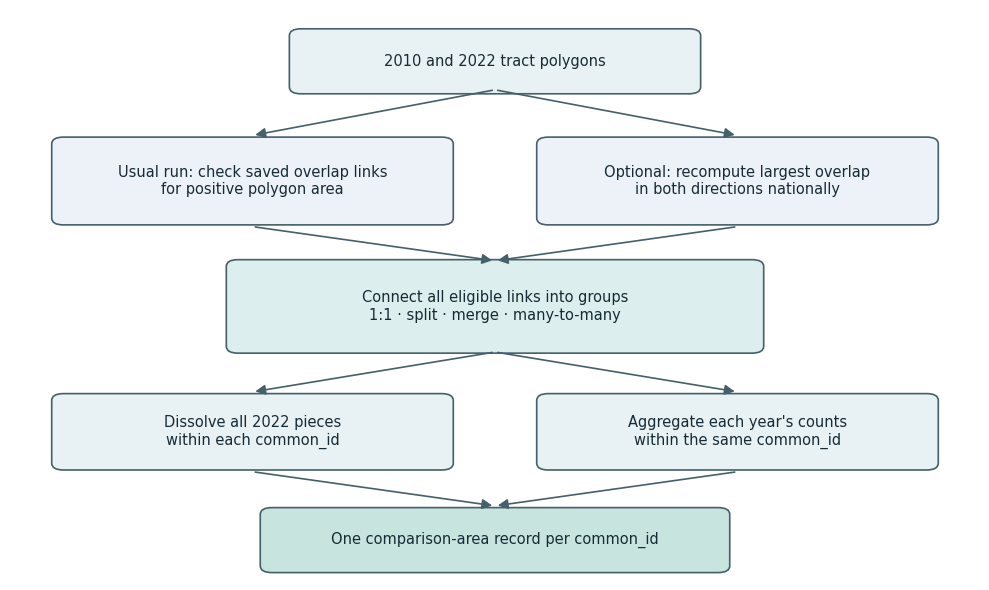

In [2]:
from processing import calculate_indicators, plot_harmonisation_flow
if REBUILD:
    calculate_indicators(PROJECT)
else:
    print("Preview: saved harmonisation and indicators; no recomputation.")
fig = plot_harmonisation_flow()
display(fig)
plt.close(fig)

## 2. Calculate indicators and export

Each year's tract data are joined through its lookup. Counts are summed within `common_id` **before** shares are calculated; each indicator keeps its own denominator and missing-value rule. Income uses household-head weights and adjusts 2010 values to July 2022 prices. Density uses an equal-area EPSG:6933 denominator; the delivered geometry remains EPSG:5880.

The exporter checks the saved harmonisation bundle and indicator fingerprints, writes clear English fields, and verifies values and geometry against its prepared input. `field_dictionary` retains every source-to-export field mapping. The municipality `overview` is simplified for display and is separate from the full-resolution analysis layer.


In [3]:
result = export_geopackage(PROJECT) if REBUILD else inspect_final(PROJECT, preview=True)
display(pd.DataFrame([{
    "common areas": result["features"],
    "municipality overview": result["overview_rows"],
    "original→English mappings": result["field_dictionary_rows"],
    "CRS": f"EPSG:{result['epsg']}"}]))
print("Local GeoPackage:", Path(result["file"]).relative_to(PROJECT))
print("SHA-256:", result["sha256"])

,common areas,municipality overview,original→English mappings,CRS
0,287178,5570,187,EPSG:5880


Local GeoPackage: datasets/census/census_comparison_areas_2010_2022.gpkg
SHA-256: 37219fc297f970d7eff71190e623cc6b106eaeb51baa4cf48725a1d99f36541f


## 3. See the group types

The table and chart count **comparison groups**, not people. A split has one 2010 tract and several 2022 tracts; a merge is the reverse. All members of either type share one `common_id` in the final analysis layer.


,type,Common areas
0,One-to-one,188105
1,Split,79455
2,Complex,15189
3,Merge,4429


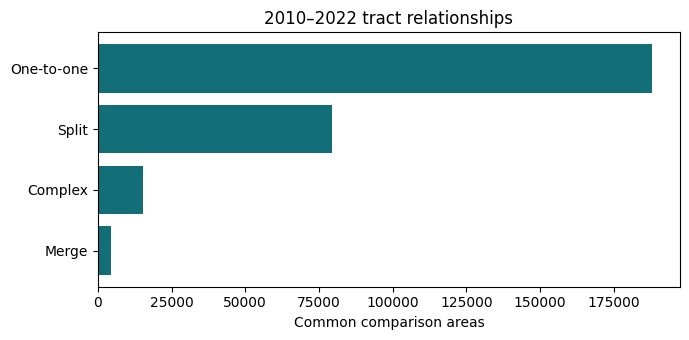

In [4]:
with sqlite3.connect(f"file:{result['file']}?mode=ro", uri=True) as db:
    relation = pd.read_sql_query('SELECT tract_relationship AS relationship, COUNT(*) AS common_areas FROM comparison_areas GROUP BY tract_relationship ORDER BY common_areas DESC', db)
labels = {"1:1": "One-to-one", "2010_to_2022_split": "Split", "2010_to_2022_merge": "Merge", "many_to_many": "Complex"}
relation["type"] = relation.relationship.map(labels).fillna(relation.relationship)
display(relation[["type", "common_areas"]].rename(columns={"common_areas": "Common areas"}))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(relation.type.iloc[::-1], relation.common_areas.iloc[::-1], color="#126f78")
ax.set_xlabel("Common comparison areas")
ax.set_title("2010–2022 tract relationships")
fig.tight_layout()
display(fig)
plt.close(fig)

**Limit:** The 2010 and 2022 footprints need not be identical. The study assumes differences mainly affect uninhabited areas; this has not been verified for every group. Unmatched tracts and footprint-difference diagnostics remain in the versioned intermediate bundle. Municipality summaries can include groups crossing municipality borders.


## Checks and handoff

The current national export contains **287,178** comparison areas, **5,570** municipality summaries, and **187** original-to-English field mappings. The pipeline checks group membership, unique IDs, input versions, CRS, missingness, source values, and geometry before publishing. The file checksum printed above identifies this exact local copy; compare it after transfer. Full independent scientific validation of the national matching remains separate from these software checks.
